In [2]:
from pathlib import Path
import pandas            as pd
import numpy             as np
import matplotlib.pyplot as plt

In [3]:
df_participantes = pd.read_csv("../datos/clean/participacions.csv")
df_carreiras = pd.read_csv("../datos/clean/carreiras.csv", sep = "/")

In [4]:
df_participantes.head()

,p_absoluto,persoa,carreira,sexo,p_sexo,categoria,p_categoria,tempo,inscrito
0,1,$2a$04$haqp5aiWUJcCCTIkCOGGle3nma.ZqvG8bLOlx75...,Montealto-3,F,14,JAV-16,90,1809.2,True
1,2,$2a$04$6RAuquXmIU/5jjBJlsJW6.1w.h7Y6O/CmoItlwO...,Hercule-1,M,10,SUB-20,7,1848.9,True
2,3,$2a$04$wEFWorRbyaQhdaVPbAfDJOVXfdo.1r2DyjKyiGE...,Hercule-1,M,10,JAV-16,66,3511.1,True
3,4,$2a$04$yXwoKDx4icCBb9Hd8VX1jO0ghLCwO6bvOTdkDkb...,Montealto-3,M,52,JUN,88,3047.3,False
4,5,$2a$04$.ch5dub46BQTcsNyyGAUfuYP/Wqw0cob53COBD....,Matogrande-2,F,48,JAV-16,43,3474.0,False


Participantes por sexo en cada carreira e evolución ao longo do circuíto.

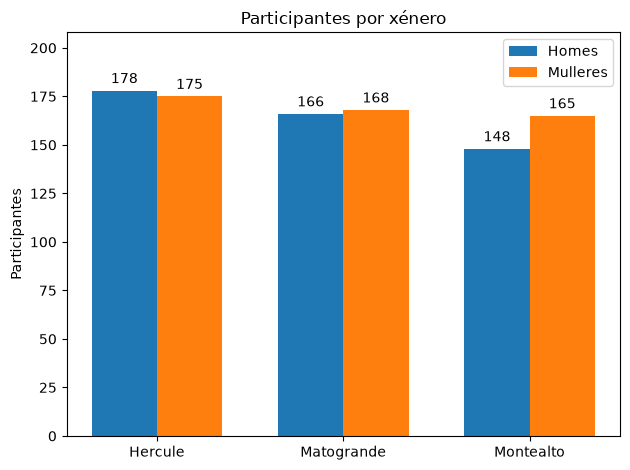

In [5]:
carreiras = [car for car in df_carreiras["nome"].unique()]
homes = []
mulleres = []
for carreira in carreiras:
    df_participantes_carreira = df_participantes[df_participantes["carreira"] == (carreira + "-" + str(carreiras.index(carreira) + 1))]
    homes.append(len(df_participantes_carreira[df_participantes_carreira["sexo"] == "M"]))
    mulleres.append(len(df_participantes_carreira[df_participantes_carreira["sexo"] == "F"]))

x = np.arange(len(carreiras))

fig, ax = plt.subplots()
rects1 = ax.bar(x - 0.35/2, homes, 0.35, label='Homes')
rects2 = ax.bar(x + 0.35/2, mulleres, 0.35, label='Mulleres')

ax.set_ylabel('Participantes')
ax.set_title('Participantes por xénero')
ax.set_xticks(x)
ax.set_xticklabels((carreiras))
ax.set_ylim((0, max(homes) + 30))
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()

plt.show()

Distribución por categorías de idade e diferenza entre sexos dentro de cada categoría.

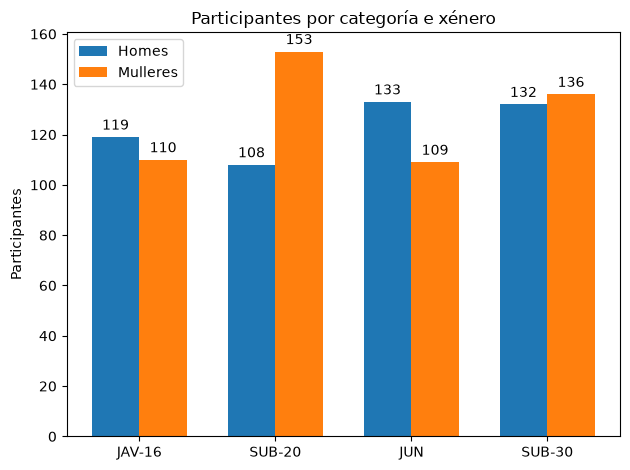

In [6]:
categorias = [cat for cat in df_participantes["categoria"].unique()]
participantes = []

for categoria in categorias:
    df_participantes_carreira = df_participantes[df_participantes["categoria"] == categoria]
    participantes.append((len(df_participantes_carreira[df_participantes_carreira["sexo"] == "M"]), len(df_participantes_carreira[df_participantes_carreira["sexo"] == "F"])))

x = np.arange(len(categorias))

fig, ax = plt.subplots()
rects1 = ax.bar(x - 0.35/2, [x[0] for x in participantes], 0.35, label='Homes')
rects2 = ax.bar(x + 0.35/2, [x[1] for x in participantes], 0.35, label='Mulleres')

ax.set_ylabel('Participantes')
ax.set_title('Participantes por categoría e xénero')
ax.set_xticks(x)
ax.set_xticklabels(categorias)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()

plt.show()

En cada carreira, que porcentaxe de participantes están inscritos no circuíto e que porcentaxe corren por proba? Cambia ao longo do ano?

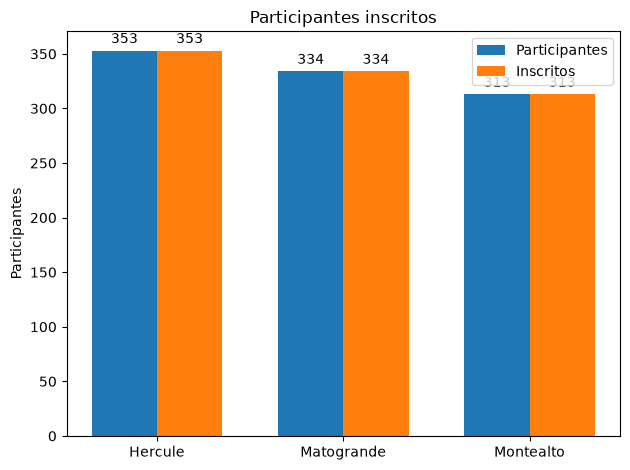

In [7]:
total_participantes = []
inscritos = []
for carreira in carreiras:
    df_participantes_carreira = df_participantes[df_participantes["carreira"] == (carreira + "-" + str(carreiras.index(carreira) + 1))]
    total_participantes.append(len(df_participantes_carreira))
    inscritos.append(len(df_participantes_carreira[df_participantes_carreira["carreira"] == (carreira + "-" + str(carreiras.index(carreira) + 1))]))

x = np.arange(len(carreiras))

fig, ax = plt.subplots()
rects1 = ax.bar(x - 0.35/2, total_participantes, 0.35, label='Participantes')
rects2 = ax.bar(x + 0.35/2, inscritos, 0.35, label='Inscritos')

ax.set_ylabel('Participantes')
ax.set_title('Participantes inscritos')
ax.set_xticks(x)
ax.set_xticklabels(carreiras)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()

plt.show()

En cantas carreiras participa de media unha persoa inscrita no circuíto? Cantas corren todas as carreiras, cantas abandonan e en que momento?

In [8]:
persoas = [persoa for persoa in df_participantes[df_participantes["inscrito"] == True]["persoa"].unique()]
participacions = []
for persoa in persoas:
    participacions.append(len(df_participantes[df_participantes["persoa"] == persoa]))

print(f"Carreiras de media nas que participa unha persoa inscrita: {sum(participacions) / len(participacions)}")
print(f"Persoas que correron en todas as carreiras: {participacions.count(len(carreiras))}")

print("TODO: Número de abandonos")

Carreiras de media nas que participa unha persoa inscrita: 1.0
Persoas que correron en todas as carreiras: 0
TODO: Número de abandonos


Repiten as persoas que corren por proba? Hai quen corre varias carreiras sen inscribirse no circuíto?

In [9]:
persoas_non_inscritas = [persoa for persoa in df_participantes[df_participantes["inscrito"] == False]["persoa"].unique()]
participacions_non_inscritas = []
for persoa in persoas:
    participacions_non_inscritas.append(len(df_participantes[df_participantes["persoa"] == persoa]))

print(f"Número de persoas que repetiron ou correron varias carreiras sen estar inscritos: {len(participacions_non_inscritas)}")

Número de persoas que repetiron ou correron varias carreiras sen estar inscritos: 501


Hai diferenzas por sexo e categoría entre inscritos no circuíto e corredores por proba?

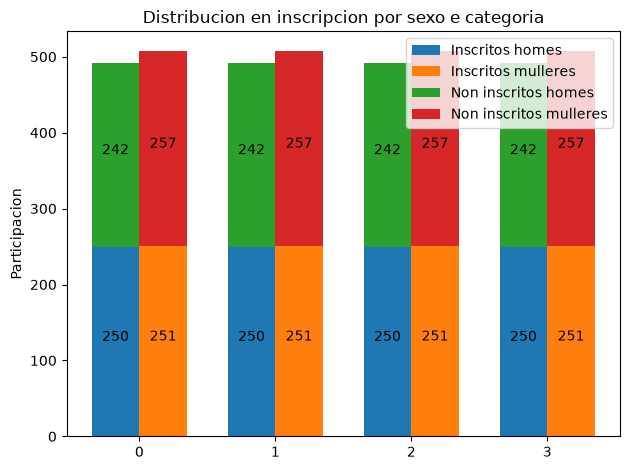

In [19]:
inscritos_homes = []
inscritos_mulleres = []
non_inscritos_homes = []
non_inscritos_mulleres = []

for categoria in categorias:
    participantes_inscritos = df_participantes[df_participantes["inscrito"] == True]
    participantes_non_inscritos = df_participantes[df_participantes["inscrito"] == False]

    inscritos_homes.append(len(participantes_inscritos[participantes_inscritos["sexo"] == "M"]))
    inscritos_mulleres.append(len(participantes_inscritos[participantes_inscritos["sexo"] == "F"]))

    non_inscritos_homes.append(len(participantes_non_inscritos[participantes_non_inscritos["sexo"] == "M"]))
    non_inscritos_mulleres.append(len(participantes_non_inscritos[participantes_non_inscritos["sexo"] == "F"]))

fig, ax = plt.subplots()

x = np.arange(len(categorias))

rects1 = ax.bar(x - 0.35/2, inscritos_homes, 0.35, label = "Inscritos homes")
rects2 = ax.bar(x + 0.35/2, inscritos_mulleres, 0.35, label = "Inscritos mulleres")
rects3 = ax.bar(x - 0.35/2, non_inscritos_homes, 0.35, bottom = inscritos_homes, label = "Non inscritos homes")
rects4 = ax.bar(x + 0.35/2, non_inscritos_mulleres, 0.35, bottom = inscritos_mulleres, label = "Non inscritos mulleres")

ax.set_ylabel('Participacion')
ax.set_title('Distribucion en inscripcion por sexo e categoria')
ax.set_xticks(x)
ax.legend()

ax.bar_label(rects1, padding=3, label_type="center")
ax.bar_label(rects2, padding=3, label_type="center")
ax.bar_label(rects3, padding=3, label_type="center")
ax.bar_label(rects4, padding=3, label_type="center")

fig.tight_layout()

plt.show()

Os inscritos no circuíto quedan en mellores postos que os corredores por proba?

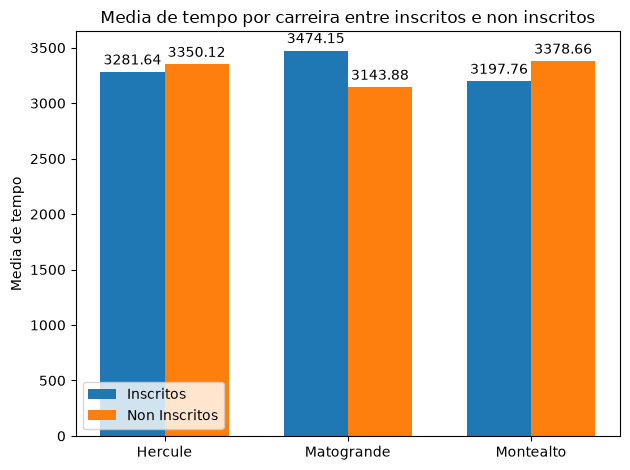

In [ ]:
medias_inscritos = []
medias_non_inscritos = []

for carreira in carreiras:
    df_participantes_carreira = df_participantes[df_participantes["carreira"] == (carreira + "-" + str(carreiras.index(carreira) + 1))]
    medias_inscritos.append(df_participantes_carreira[df_participantes_carreira["inscrito"] == True]["tempo"].mean())
    medias_non_inscritos.append(df_participantes_carreira[df_participantes_carreira["inscrito"] == False]["tempo"].mean())

x = np.arange(len(carreiras))

fig, ax = plt.subplots()
rects1 = ax.bar(x - 0.35/2, medias_inscritos, 0.35, label='Inscritos')
rects2 = ax.bar(x + 0.35/2, medias_non_inscritos, 0.35, label='Non Inscritos')

ax.set_ylabel('Media de tempo')
ax.set_title('Media de tempo por carreira entre inscritos e non inscritos')
ax.set_xticks(x)
ax.set_xticklabels(carreiras)
ax.legend()

ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

fig.tight_layout()

plt.show()

Distribución dos tempos por categoría e sexo.

In [ ]:
medias = []

for carreira in carreiras:
    df_participantes_carreira = df_participantes[df_participantes["carreira"] == (carreira + "-" + str(carreiras.index(carreira) + 1))]

    for categoria in categorias:
        df_part_cat = df_participantes_carreira[df_participantes_carreira["categoria"] == (carreira + "-" + str(carreiras.index(carreira) + 1))]

        dic = {"Homes" : 0, "Mulleres" : 0}

        dic["Homes"] = df_part_cat[df_part_cat["sexo"] == "M"]["tempo"].mean()
        dic["Mulleres"] = df_part_cat[df_part_cat["sexo"] == "F"]["tempo"].mean()

        medias.append({categoria:dic})

print(medias)

[{'JAV-16': {'Homes': nan, 'Mulleres': nan}}, {'SUB-20': {'Homes': nan, 'Mulleres': nan}}, {'JUN': {'Homes': nan, 'Mulleres': nan}}, {'SUB-30': {'Homes': nan, 'Mulleres': nan}}, {'JAV-16': {'Homes': nan, 'Mulleres': nan}}, {'SUB-20': {'Homes': nan, 'Mulleres': nan}}, {'JUN': {'Homes': nan, 'Mulleres': nan}}, {'SUB-30': {'Homes': nan, 'Mulleres': nan}}, {'JAV-16': {'Homes': nan, 'Mulleres': nan}}, {'SUB-20': {'Homes': nan, 'Mulleres': nan}}, {'JUN': {'Homes': nan, 'Mulleres': nan}}, {'SUB-30': {'Homes': nan, 'Mulleres': nan}}]


Quen mellora máis entre a primeira e a última carreira en que participa? Melloran máis os inscritos no circuíto?

In [ ]:
mais_mellora = ""
tempo_mais_mellora = 0

mellora_inscritos = 0
mellora_non_inscritos = 0

for persoa in persoas:
    df_carreiras = df_participantes[df_participantes["persoa"] == persoa]

    if(len(df_carreiras) > 1):
        mellora = df_carreiras.iloc[0] - df_carreiras.iloc[len(df_carreiras)]
        
        if mellora > tempo_mais_mellora:
            mais_mellora = persoa
            tempo_mais_mellora = mellora
        
        if df_carreiras.iloc[0]["inscrito"] == True:
            mellora_inscritos += mellora
        else:
            mellora_non_inscritos += mellora

mellora_media_ins = mellora_inscritos / len(df_participantes[df_participantes["inscrito"] == True])
mellora_media_n_ins = mellora_non_inscritos / len(df_participantes[df_participantes["inscrito"] == False])

print(f"A persoa que mais mellorou foi: {mais_mellora}, cunha mellora de {tempo_mais_mellora} segundos.")
print(f"De media, os inscritos melloran {mellora_media_ins}, mentras que os non inscritos {mellora_media_n_ins}")

A persoa que mais mellorou foi: , cunha mellora de 0 segundos.
De media, os inscritos melloran 0.0, mentras que os non inscritos 0.0
